Project: Music Emotion Analysis

Objective: Analyzing the relationship between music and human emotions using data science and machine learning.

1.Music Dataset Indexing and Grouping
2.Dataset: MUSE v3 (90,001 Music Tracks)
3.Objective: Organize music records and analyze emotional
4.characteristics across different music genres.


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('muse_v3.csv')
df.sample(5)

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
85353,https://www.last.fm/music/terry%2bpollard/_/au...,Autumn Serenade,Terry Pollard,['lively'],1,7.120000,6.100000,6.860000,NaN,0y5JVCiL2v7bKgnQPdbVuM,jazz
57033,https://www.last.fm/music/wolfgang%2bamadeus%2...,"Requiem in D minor, K. 626 - XV. Lux aeterna",Wolfgang Amadeus Mozart,"['elegant', 'refined']",2,6.555000,4.190000,6.310000,6696f168-e223-4465-95c3-7b1bceb5a2fe,0vqSzTjkgzS7yqwHouCwzt,focus
26918,https://www.last.fm/music/vitamin%2bc/_/about%...,About Last Night,Vitamin C,['brash'],3,6.206667,4.593333,5.923333,NaN,3MrQ9oFAkxncVipPFEvtBs,pop
73192,https://www.last.fm/music/mason%2bproper/_/100...,100 Years,Mason Proper,"['summery', 'whimsical']",8,6.431250,4.668750,5.320000,NaN,4KsWWRAF2pWDbRfyttXUk6,indie
34574,https://www.last.fm/music/wendy%2b%2526%2blisa...,Sweet Suite (Beginning at the End),Wendy & Lisa,['ornate'],4,4.830000,3.910000,4.170000,11551721-08f7-4b40-9112-2861282cb03d,58ikfkhrSVRZMtNWUePmJI,funk


In [5]:
df.head(10)

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
0,https://www.last.fm/music/eminem/_/%2527till%2...,'Till I Collapse,Eminem,['aggressive'],6,4.550000,5.273125,5.690625,cab93def-26c5-4fb0-bedd-26ec4c1619e1,4xkOaSrkexMciUUogZKVTS,rap
1,https://www.last.fm/music/metallica/_/st.%2banger,St. Anger,Metallica,['aggressive'],8,3.710000,5.833000,5.427250,727a2529-7ee8-4860-aef6-7959884895cb,3fOc9x06lKJBhz435mInlH,metal
2,https://www.last.fm/music/rick%2bross/_/speedi...,Speedin',Rick Ross,['aggressive'],1,3.080000,5.870000,5.490000,NaN,3Y96xd4Ce0J47dcalLrEC8,rap
3,https://www.last.fm/music/m.i.a./_/bamboo%2bbanga,Bamboo Banga,M.I.A.,"['aggressive', 'fun', 'sexy', 'energetic']",13,6.555071,5.537214,5.691357,99dd2c8c-e7c1-413e-8ea4-4497a00ffa18,6tqFC1DIOphJkCwrjVzPmg,hip-hop
4,https://www.last.fm/music/dope/_/die%2bmf%2bdie,Die MF Die,Dope,['aggressive'],7,3.771176,5.348235,5.441765,b9eb3484-5e0e-4690-ab5a-ca91937032a5,5bU4KX47KqtDKKaLM4QCzh,metal
5,https://www.last.fm/music/drowning%2bpool/_/st...,Step Up,Drowning Pool,['aggressive'],9,2.971389,5.537500,4.726389,49e7b4d2-3772-4301-ba25-3cc46ceb342e,4Q1w4Ryyi8KNxxaFlOQClK,metal
6,https://www.last.fm/music/kanye%2bwest/_/feedback,Feedback,Kanye West,['aggressive'],1,3.080000,5.870000,5.490000,NaN,49fT6owWuknekShh9utsjv,hip-hop
7,https://www.last.fm/music/deftones/_/7%2bwords,7 Words,Deftones,"['aggressive', 'angry']",10,3.807121,5.473939,4.729091,1a826083-5585-445f-a708-415dc90aa050,6DoXuH326aAYEN8CnlLmhP,nu metal
8,https://www.last.fm/music/fiona%2bapple/_/limp,Limp,Fiona Apple,"['aggressive', 'angry', 'bitter']",20,3.737211,5.610204,4.626735,4435982c-b83e-4daa-af2b-9f3430036bb7,104YdibC7VQy78xAVmgRYr,singer-songwriter
9,https://www.last.fm/music/metallica/_/sweet%2b...,Sweet Amber,Metallica,['aggressive'],4,3.582759,5.757241,5.340000,fe1cc051-faa7-4953-b331-f6196cd3ddae,5fU6qjmD38P90BMsuqpiuU,metal


In [6]:
df.shape

(90001, 11)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90001 entries, 0 to 90000
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   lastfm_url              90001 non-null  str    
 1   track                   90001 non-null  str    
 2   artist                  90001 non-null  str    
 3   seeds                   90001 non-null  str    
 4   number_of_emotion_tags  90001 non-null  int64  
 5   valence_tags            90001 non-null  float64
 6   arousal_tags            90001 non-null  float64
 7   dominance_tags          90001 non-null  float64
 8   mbid                    61217 non-null  str    
 9   spotify_id              61630 non-null  str    
 10  genre                   83362 non-null  str    
dtypes: float64(3), int64(1), str(7)
memory usage: 7.6 MB


In [8]:
df.describe()

,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags
count,90001.000000,90001.000000,90001.000000,90001.000000
mean,3.987745,5.454280,4.317691,5.246029
std,4.153822,1.553079,1.154948,1.171096
min,1.000000,0.235000,0.108113,0.229231
25%,1.000000,4.277500,3.527500,4.550194
50%,2.000000,5.650000,4.330000,5.460000
75%,5.000000,6.696667,5.150000,6.115443
max,50.000000,8.475000,7.270000,7.440000


In [9]:
df.isnull().sum()

lastfm_url                    0
track                         0
artist                        0
seeds                         0
number_of_emotion_tags        0
valence_tags                  0
arousal_tags                  0
dominance_tags                0
mbid                      28784
spotify_id                28371
genre                      6639
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.corr(numeric_only=True)

,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags
number_of_emotion_tags,1.000000,0.049745,-0.101912,0.001776
valence_tags,0.049745,1.000000,0.405396,0.861876
arousal_tags,-0.101912,0.405396,1.000000,0.469441
dominance_tags,0.001776,0.861876,0.469441,1.000000


In [12]:
df.sort_values(by="number_of_emotion_tags", ascending=True).head(10)

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
39,https://www.last.fm/music/method%2bman/_/meth%...,Meth Vs. Chef,Method Man,['aggressive'],1,3.08,5.87,5.49,1bc10267-18e2-458a-9f16-bf5bc07392b1,5o9jJ0aRyn7WswL4giBmMB,hip-hop
34,https://www.last.fm/music/slipknot/_/custer,Custer,Slipknot,['aggressive'],1,3.08,5.87,5.49,b6b7e79d-a4c9-44ae-b0ee-b1fcc0475833,3GiJq4AQK7324mfIQbpiTf,nu metal
89983,https://www.last.fm/music/quietdrive/_/secret,Secret,Quietdrive,['transparent'],1,5.37,3.45,5.33,909ba2e0-6076-4ad8-8be9-a335725de4ef,2bRIsZ92JRKlvQOZlyR9CO,NaN
89982,https://www.last.fm/music/trans%2bam/_/white%2...,White Rhino,Trans Am,['transparent'],1,5.37,3.45,5.33,e9b42334-5ee1-4b02-941a-701b7493a674,7tf8JaHcW0mZ2plqW2h0k7,NaN
57770,https://www.last.fm/music/chris%2bbathgate/_/t...,The Last Wine of Winter,Chris Bathgate,['lyrical'],1,6.84,3.81,5.76,0518c840-631d-4dee-8415-c247812592c0,NaN,indie
57768,https://www.last.fm/music/salif%2bkeita/_/m%25...,M'Bemba,Salif Keita,['lyrical'],1,6.84,3.81,5.76,NaN,NaN,world
57763,https://www.last.fm/music/aceyalone/_/takeoff,Takeoff,Aceyalone,['lyrical'],1,6.84,3.81,5.76,b876045f-186a-4664-ab22-2e6af85fec44,5p0fOPtaggTF8iR1rHxIdw,hip hop
57788,https://www.last.fm/music/brian%2bcrain/_/anda...,Andante Cantabile,Brian Crain,['lyrical'],1,6.84,3.81,5.76,524655cd-95d4-42df-9828-a32a83dbeca1,1Y9Wg6PoDtYNGVbyhUom9H,piano
57787,https://www.last.fm/music/vendetta%2bred/_/sta...,Stay Home,Vendetta Red,['lyrical'],1,6.84,3.81,5.76,3fe9573c-7cdc-444b-ad5d-160120333da5,4RNapqAcaIi40sEkmOStfv,alternative
57786,https://www.last.fm/music/within%2btemptation/...,Somewhere (feat Anneke van Gie,Within Temptation,['lyrical'],1,6.84,3.81,5.76,NaN,6iPA4rfysi2ijan9UAvoKB,acoustic


In [13]:
df.sort_values(by="number_of_emotion_tags", ascending=False).head(10)

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
2129,https://www.last.fm/music/alaska/_/bloodfeast,Bloodfeast,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",50,4.373611,4.951389,4.826667,NaN,NaN,rock
2135,https://www.last.fm/music/alaska/_/juan,Juan,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,0kl9Jbplh4hZCaj5YdjptI,rock
2144,https://www.last.fm/music/alaska/_/blacklist,Blacklist,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,6icgmtt5Jc9B34DotG4B9k,math rock
2136,https://www.last.fm/music/alaska/_/electric%2b...,Electric Death Song,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,7kjxRuYb4ZTy5mHg358UJG,rock
2140,https://www.last.fm/music/alaska/_/three%2bcro...,Three Crosses,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,6OIhcpRlqHxfSlsaf75SJg,math rock
2143,https://www.last.fm/music/alaska/_/sacking%2bo...,Sacking Offence,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,4IqaOOkX6571RjQpCeK65k,alternative
2142,https://www.last.fm/music/alaska/_/noose,Noose,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,14OTH0zEQkFMcso5wuTqCQ,rock
2139,https://www.last.fm/music/alaska/_/chungi,Chungi,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",49,4.402000,4.917714,4.864857,NaN,6iXob6JUuUW4HOP9jpMZOW,rock
6507,https://www.last.fm/music/xiu%2bxiu/_/el%2bnaco,El Naco,Xiu Xiu,"['menacing', 'scary music', 'unsettling', 'eer...",47,2.875720,5.010026,3.732579,1df4d04e-2691-458d-93c2-be2d31fb8398,2tLvBR5PbDi3lzsZPxQNJ2,noise
2133,https://www.last.fm/music/alaska/_/sweet%2bcar...,Sweet Caroline,Alaska,"['confrontational', 'fierce', 'harsh', 'hostil...",41,4.111724,4.984138,4.746552,NaN,NaN,post-punk


In [14]:
df[df.isnull().any(axis=1)]

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
2,https://www.last.fm/music/rick%2bross/_/speedi...,Speedin',Rick Ross,['aggressive'],1,3.080000,5.870000,5.490000,NaN,3Y96xd4Ce0J47dcalLrEC8,rap
6,https://www.last.fm/music/kanye%2bwest/_/feedback,Feedback,Kanye West,['aggressive'],1,3.080000,5.870000,5.490000,NaN,49fT6owWuknekShh9utsjv,hip-hop
28,https://www.last.fm/music/beck/_/mutherfuker,Mutherfuker,Beck,['aggressive'],9,4.899213,5.558539,5.174494,ccf93ad3-ed73-46c3-9993-91633ee45aa8,NaN,rock
29,https://www.last.fm/music/seether/_/i%2527m%2b...,I'm the One,Seether,"['aggressive', 'dark']",2,4.080000,4.980000,5.050000,5cb8474a-8603-4ff9-8a3a-77043e74bb1c,NaN,rock
31,https://www.last.fm/music/the%2banimals/_/i%25...,I'm Crying,The Animals,['aggressive'],7,3.484407,4.272034,5.241695,19aa367b-bda0-4d04-a66c-78e7216be351,NaN,rock
...,...,...,...,...,...,...,...,...,...,...,...
89995,https://www.last.fm/music/%25e9%2587%258d%25e6...,RAINY,重松俊一,['transparent'],1,5.370000,3.450000,5.330000,NaN,NaN,video game music
89996,https://www.last.fm/music/gaby%2bhoffmann%2b%2...,Battle,Gaby Hoffmann & Jay Duplass,['transparent'],1,5.370000,3.450000,5.330000,NaN,NaN,NaN
89997,https://www.last.fm/music/omar%2brodriguez-lop...,Hands Tied to the Roots of a Hemorrhage,Omar Rodriguez-Lopez,['transparent'],4,5.797887,4.132254,5.570563,NaN,NaN,progressive rock
89998,https://www.last.fm/music/ace%2bwhite/_/crookf...,Crookfield Zoo,Ace White,['transparent'],1,5.370000,3.450000,5.330000,NaN,NaN,NaN


In [15]:
df.dropna(inplace=True)

In [20]:
df.isnull().sum()

lastfm_url                0
track                     0
artist                    0
seeds                     0
number_of_emotion_tags    0
valence_tags              0
arousal_tags              0
dominance_tags            0
mbid                      0
spotify_id                0
genre                     0
dtype: int64

B.Indexing & Grouping:

1.Set track names or unique identifiers as the dataset index
to organize and access music records efficiently.

2.Group music tracks by genre and analyze their average valence, arousal, and dominance scores.


In [19]:
df_valence_tags = df.groupby('number_of_emotion_tags')
df_valence_tags.describe()
df_valence_tags

In [22]:
df_valence_tags.describe()['valence_tags'].sort_values(by='mean',ascending=True)

,count,mean,std,min,25%,50%,75%,max
number_of_emotion_tags,,,,,,,,
47,1.0,2.875720,NaN,2.875720,2.875720,2.875720,2.875720,2.875720
36,1.0,2.945455,NaN,2.945455,2.945455,2.945455,2.945455,2.945455
30,1.0,4.998607,NaN,4.998607,4.998607,4.998607,4.998607,4.998607
32,3.0,5.050598,0.307060,4.754667,4.892052,5.029437,5.198564,5.367692
33,4.0,5.177918,0.304359,4.815806,4.981374,5.230421,5.426965,5.435023
2,10002.0,5.280820,1.792981,0.250370,3.822853,5.570000,6.771101,8.445000
27,16.0,5.330554,0.697103,3.879027,5.029630,5.323783,5.806809,6.739375
3,7104.0,5.340149,1.663351,0.235000,4.103333,5.546005,6.761846,8.358947
4,4955.0,5.412369,1.507952,0.767788,4.327500,5.536000,6.633732,8.275263


In [23]:
df[df['valence_tags']=='number_of_emotion_tags']

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre


In [26]:
df_valence_tags.describe()['valence_tags'].sort_values(by='mean',ascending=False)

,count,mean,std,min,25%,50%,75%,max
number_of_emotion_tags,,,,,,,,
29,2.0,6.178612,0.326700,5.947600,6.063106,6.178612,6.294118,6.409623
31,2.0,5.961815,0.417403,5.666667,5.814241,5.961815,6.109390,6.256964
13,646.0,5.912169,1.063438,1.990206,5.304445,6.020975,6.660861,8.041641
14,545.0,5.851002,1.016068,2.388333,5.215915,5.970988,6.570270,8.019225
24,41.0,5.827324,0.785825,3.802714,5.433433,6.070259,6.269364,7.130000
11,811.0,5.808514,1.220763,2.331600,5.011980,5.944545,6.748691,8.206641
10,1000.0,5.803513,1.170308,1.671226,5.111007,5.831111,6.695238,8.156696
9,1105.0,5.789278,1.226895,1.237863,5.027500,5.930000,6.668732,8.121194
15,492.0,5.781668,0.932065,3.008462,5.187420,5.836794,6.468073,8.032529


In [40]:
df = df.replace('number_of_emotion_tags','artist')
df_valence_tags = df.groupby('valence_tags')

In [41]:
df_valence_tags.describe()['number_of_emotion_tags'].sort_values(by='mean',ascending=False)

,count,mean,std,min,25%,50%,75%,max
valence_tags,,,,,,,,
2.875720,1.0,47.0,NaN,47.0,47.0,47.0,47.0,47.0
5.697157,1.0,40.0,NaN,40.0,40.0,40.0,40.0,40.0
5.791404,1.0,40.0,NaN,40.0,40.0,40.0,40.0,40.0
5.607477,1.0,40.0,NaN,40.0,40.0,40.0,40.0,40.0
4.582073,1.0,40.0,NaN,40.0,40.0,40.0,40.0,40.0
...,...,...,...,...,...,...,...,...
5.400000,1.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0
2.100000,8.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
7.050000,4.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


In [42]:
df['number_of_emotion_tags'].value_counts()

number_of_emotion_tags
1     10524
2     10002
3      7104
4      4955
5      3261
6      2280
7      1778
8      1402
9      1105
10     1000
11      811
12      701
13      646
14      545
15      492
16      389
17      349
18      272
19      213
20      193
21      134
22       91
23       63
24       41
25       25
27       16
26       15
28        6
33        4
40        4
32        3
34        2
37        2
39        2
38        2
29        2
31        2
30        1
47        1
36        1
35        1
Name: count, dtype: int64

In [43]:
df['valence_tags'].value_counts()

valence_tags
3.850000    515
3.080000    299
5.000000    283
6.840000    283
7.250000    280
           ... 
7.003258      1
3.300000      1
3.680274      1
3.598243      1
6.290784      1
Name: count, Length: 23362, dtype: int64

In [45]:
df.sort_values(by='valence_tags',ascending=False).head(1)

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
40437,https://www.last.fm/music/brandon%2bflowers/_/...,Was It Something I Said?,Brandon Flowers,['happy'],1,8.47,6.05,7.21,47e710bc-0020-4710-8dfb-54d3c9be8eab,4pJsShBtIuywbhoK8khcai,indie


In [46]:
df.sort_values(by='valence_tags',ascending=True).head(1)

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
73265,https://www.last.fm/music/beastie%2bboys/_/che...,check it out,Beastie Boys,['summery'],3,0.235,0.134808,0.229231,6abb2735-b0f5-4778-bef8-b42c802ce786,56H98l4uinRifnTH8e308N,hip-hop


In [48]:
df['valence_tags'].mean()

np.float64(5.516191736789908)

In [49]:
df.corr(numeric_only=True)

,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags
number_of_emotion_tags,1.000000,0.071565,-0.094457,0.029837
valence_tags,0.071565,1.000000,0.421238,0.871333
arousal_tags,-0.094457,0.421238,1.000000,0.472122
dominance_tags,0.029837,0.871333,0.472122,1.000000


Text(0, 0.5, 'number_of_emotion_tags')

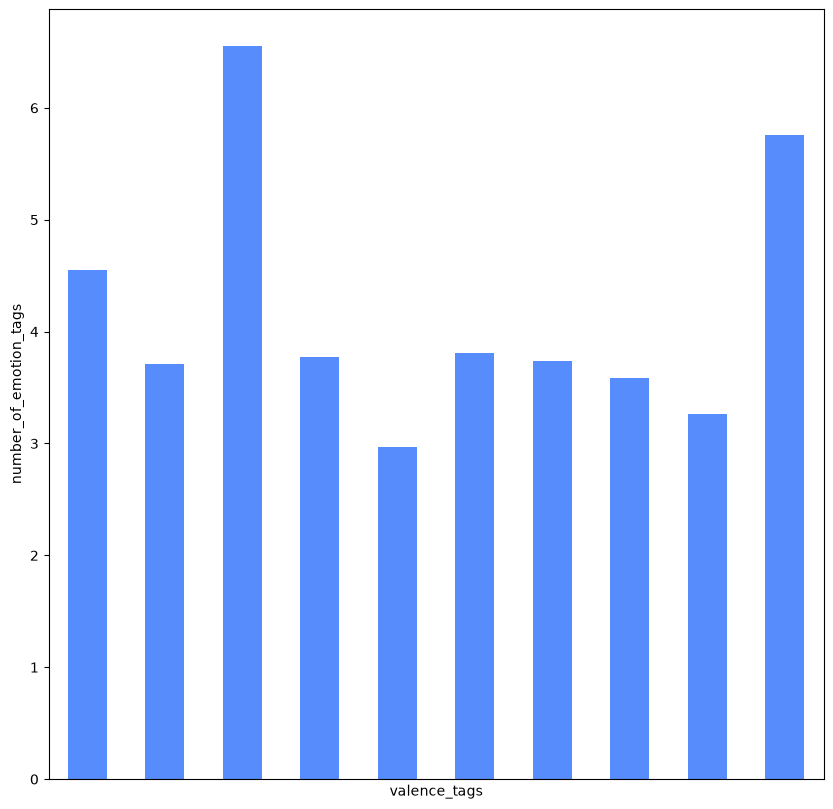

In [27]:
df.set_index('number_of_emotion_tags')['valence_tags'].head(10).plot(xticks=np.arange(7,6),kind='bar',figsize=(10,10))
plt.xlabel('valence_tags')
plt.ylabel('number_of_emotion_tags')

(array([3.5846e+04, 7.5650e+03, 2.7030e+03, 1.7150e+03, 4.8100e+02,
        1.0300e+02, 1.2000e+01, 6.0000e+00, 8.0000e+00, 1.0000e+00]),
 array([ 1. ,  5.6, 10.2, 14.8, 19.4, 24. , 28.6, 33.2, 37.8, 42.4, 47. ]),
 <BarContainer object of 10 artists>)

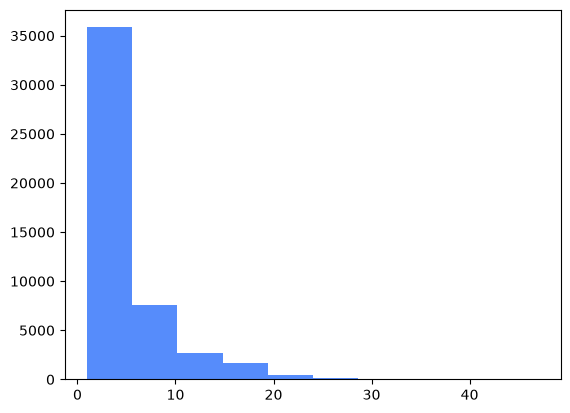

In [28]:
plt.hist(df['number_of_emotion_tags'])

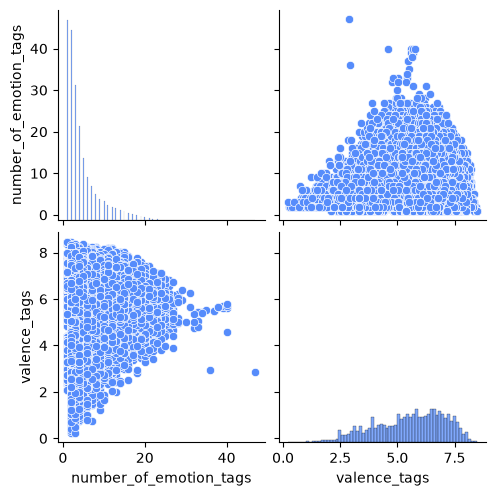

In [29]:
sns.pairplot(df[['number_of_emotion_tags', 'valence_tags']])

In [57]:
df.corr(numeric_only=True)['valence_tags']

number_of_emotion_tags    0.071565
valence_tags              1.000000
arousal_tags              0.421238
dominance_tags            0.871333
Name: valence_tags, dtype: float64

<Axes: >

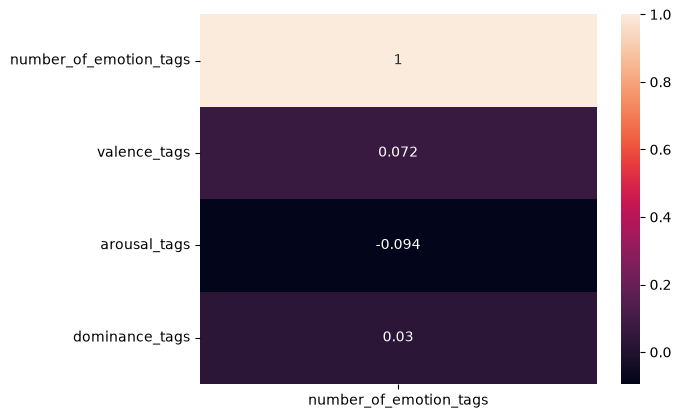

In [30]:
sns.heatmap(df.corr(numeric_only=True)['number_of_emotion_tags'].to_frame(),annot=True)

<Axes: >

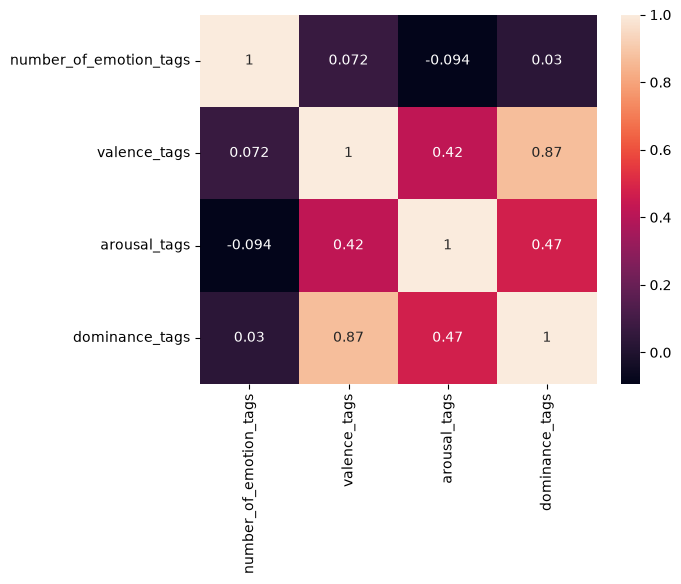

In [31]:
sns.heatmap(df.corr(numeric_only=True),annot=True)